# Chapter 12 – Example 12.1
## Multicriterial Evaluation of Optimization Methods

* **Book:** Four-Bar Mechanism Design using GA and Neural Networks  
* **Objective:** Compare GA, DE, PSO, and hybrid GA-NN under five weighted criteria and visualize the results using a radar chart.

### 1. Weighted Score

In [7]:
from numpy import *

# Evaluation criteria (Scale from 1 to 10)
# Columns: Accuracy, Speed, Robustness, Implementation, Scalability
CRITERIOS = array([
    [  8.5,  7.0,  8.0,  9.0,  7.5 ],  # Classic GA
    [  8.0,  6.5,  8.5,  7.0,  8.0 ],  # Differential Evolution (DE)
    [  7.5,  7.5,  7.0,  7.5,  7.0 ],  # PSO
    [  9.0,  5.5,  8.5,  6.0,  9.0 ],  # Hybrid GA-NN
])

METODOS = ['Classic GA', 'DE', 'PSO', 'Hybrid GA-NN']
COLS    = ['Accuracy', 'Speed', 'Robustness', 'Implementation', 'Scalability']
PESOS   = array([0.30, 0.20, 0.25, 0.15, 0.10])  # Total sum = 1.0

puntuacion = CRITERIOS @ PESOS

print("Multicriterial evaluation of optimization methods")
print("=" * 65)
print(f"{'Method':>16}", end="")
for c in COLS:
    print(f"  {c[:5]:>5}", end="")
print(f"  {'Total':>7}")
print("-" * 65)

for i, m in enumerate(METODOS):
    print(f"{m:>16}", end="")
    for j in range(len(COLS)):
        print(f"  {CRITERIOS[i, j]:>5.1f}", end="")
    print(f"  {puntuacion[i]:>7.3f}")
print("-" * 65)

mejor_idx = argmax(puntuacion)
print(f"\nBest method: {METODOS[mejor_idx]} (Score = {puntuacion.max():.3f})")

rankings = [METODOS[i] for i in argsort(-puntuacion)]
print(f"Preference rankings: {', '.join(rankings)}")

Multicriterial evaluation of optimization methods
          Method  Accur  Speed  Robus  Imple  Scala    Total
-----------------------------------------------------------------
      Classic GA    8.5    7.0    8.0    9.0    7.5    8.050
              DE    8.0    6.5    8.5    7.0    8.0    7.675
             PSO    7.5    7.5    7.0    7.5    7.0    7.325
    Hybrid GA-NN    9.0    5.5    8.5    6.0    9.0    7.725
-----------------------------------------------------------------

Best method: Classic GA (Score = 8.050)
Preference rankings: Classic GA, Hybrid GA-NN, DE, PSO


### 2. Radar Chart

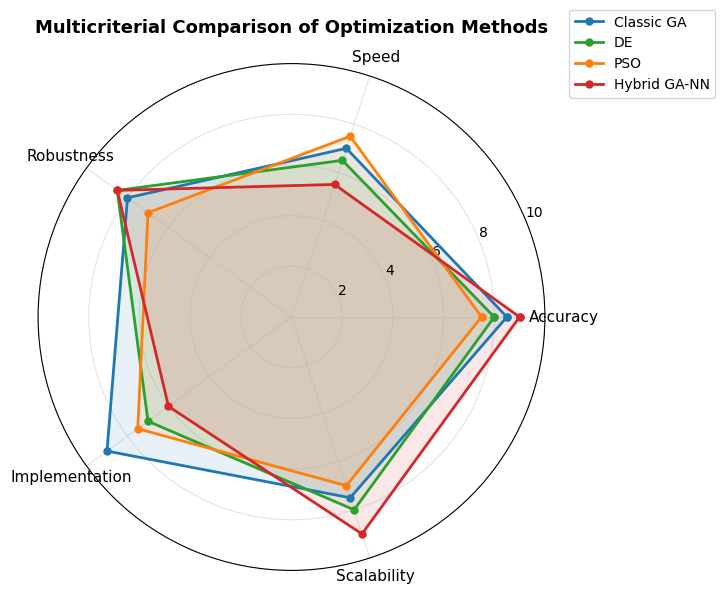

Figure successfully saved: fig12_1_radar.png


In [8]:
from numpy import *
import matplotlib.pyplot as plt

criterios = ['Accuracy', 'Speed', 'Robustness', 'Implementation', 'Scalability']
N = len(criterios)

# Configure angles for the polar diagram
angles = list(linspace(0, 2 * pi, N, endpoint=False)) + [0]
colores = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']

fig, ax = plt.subplots(figsize=(7, 6), subplot_kw=dict(polar=True))

for i, (d, m, c) in enumerate(zip(CRITERIOS, METODOS, colores)):
    vals = d.tolist() + d[:1].tolist()
    ax.plot(angles, vals, 'o-', linewidth=2, label=m, color=c, markersize=5)
    ax.fill(angles, vals, alpha=0.10, color=c)

ax.set_thetagrids(degrees(angles[:-1]), criterios, fontsize=11)
ax.set_ylim(0, 10)
ax.set_title('Multicriterial Comparison of Optimization Methods',
             pad=22, fontsize=13, fontweight='bold')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.12), fontsize=10)
ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig('fig12_1_radar.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure successfully saved: fig12_1_radar.png")

### 3. Weights Sensitivity Analysis

In [9]:
from numpy import *

# Sensitivity analysis: How does the ranking change when varying the 'Accuracy' weight?
print("Ranking sensitivity when varying the weight of Accuracy (w_Acc)")
print(f"{'w_Acc':>8}  {'1st Place':>16}  {'2nd Place':>16}  {'3rd Place':>16}  {'4th Place':>16}")
print("-" * 80)

for w_p in [0.10, 0.20, 0.30, 0.40, 0.50]:
    # Create a new weight vector modifying the accuracy weight while maintaining the proportion
    ws = array([w_p, 0.20, 0.25, 0.15, 0.10])
    ws = ws / ws.sum()   # Renormalize to sum up to 1.0

    pts = CRITERIOS @ ws
    rank = [METODOS[i] for i in argsort(-pts)]
    print(f"{w_p:>8.2f}  {rank[0]:>16}  {rank[1]:>16}  {rank[2]:>16}  {rank[3]:>16}")

Ranking sensitivity when varying the weight of Accuracy (w_Acc)
   w_Acc         1st Place         2nd Place         3rd Place         4th Place
--------------------------------------------------------------------------------
    0.10        Classic GA                DE      Hybrid GA-NN               PSO
    0.20        Classic GA                DE      Hybrid GA-NN               PSO
    0.30        Classic GA      Hybrid GA-NN                DE               PSO
    0.40        Classic GA      Hybrid GA-NN                DE               PSO
    0.50        Classic GA      Hybrid GA-NN                DE               PSO
